# Notebook 4: Box, Papers and Seller Analysis (Dataset 2)

**Project:** Luxury Watch Resale Price Analysis (final capstone)
**Author:** Mina Andrawos

Dataset 1 has no information on box & papers or on the seller. Dataset 2 (about 42,000 listings) does. This notebook models Dataset 2 to answer two practical questions a seller would ask:
1. **How much more is a watch worth with its original box and papers?**
2. **Do trusted or highly-reviewed sellers get higher prices for comparable watches?**

It also gives a like-for-like comparison with the initial report's Ridge baseline (R² = 0.80), which was built on this dataset.

| # | Notebook | Purpose |
|---|---|---|
| 1 | [Data cleaning and EDA](01_data_cleaning_and_eda.ipynb) | Clean both datasets, engineer features, explore price drivers |
| 2 | [Model training and tuning](02_model_training_and_tuning.ipynb) | Compare five model types with cross-validation and grid search |
| 3 | [Model evaluation and insights](03_model_evaluation_and_insights.ipynb) | Test-set results, error analysis, feature importance, price premiums |
| **4** | **Box, papers and seller analysis (this notebook)** | Measure the value of box, papers and seller reputation |

### Notebook outline
1. Setup and data
2. Features, metric and validation
3. Grid search and cross-validated model comparison
4. Test-set results vs the initial baseline
5. Feature importance
6. What are box, papers and seller reputation worth?
7. Summary

## 1. Setup and Data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from threadpoolctl import threadpool_limits

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")

# Gradient boosting runs much faster here with one OpenMP thread per model; the speed-up comes
# instead from running cross-validation folds in parallel (n_jobs=-1)
threadpool_limits(limits=1, user_api="openmp")

RANDOM_STATE = 42
IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(exist_ok=True)

market = pd.read_parquet("data/processed/market_clean.parquet")
# Seller counts are very skewed (a few dealers have tens of thousands of reviews), so they enter the model as log(1 + count)
market["log_seller_reviews"] = np.log1p(market["seller_reviews"])
market["log_seller_watches_sold"] = np.log1p(market["seller_watches_sold"])
print(f"Dataset 2: {market.shape[0]:,} listings")

Dataset 2: 42,214 listings


## 2. Features, Metric and Validation
> *As was done in the initial report: Ridge Regression with the initial features on Dataset 2. It is re-run here on purpose, as a like-for-like baseline for the new models and features.*

Two feature sets are compared:
- **Initial features** (as in the initial report): brand, movement, case material, condition, gender, watch age, box and papers.
- **Extended features**: the initial features plus bracelet material, case shape, crystal, dial colour, face area, water resistance and the seller variables (trusted-seller, fast-shipper and punctuality badges, number of reviews, number of watches sold).

The metric and validation strategy are the same as in Notebook 2: **RMSE on log10 price** as the primary metric (penalizes large relative mispricings), R² and median absolute percentage error (MdAPE) as supporting metrics, an 80/20 train/test split, and 5-fold cross-validated grid search on the training set. Dataset 2 is small enough to tune on the full training set.

In [2]:
INITIAL_CATEGORICAL = ["movement", "case_material", "condition", "gender"]
INITIAL_NUMERIC = ["watch_age", "has_box", "has_papers"]
EXTRA_CATEGORICAL = ["bracelet_material", "shape", "crystal", "dial"]
EXTRA_NUMERIC = ["face_area", "water_resistance", "trusted_seller", "fast_shipper", "punctual_seller",
                 "log_seller_reviews", "log_seller_watches_sold"]

FEATURE_SETS = {
    "Initial features": {"categorical": INITIAL_CATEGORICAL, "numeric": INITIAL_NUMERIC},
    "Extended features": {"categorical": INITIAL_CATEGORICAL + EXTRA_CATEGORICAL,
                          "numeric": INITIAL_NUMERIC + EXTRA_NUMERIC},
}
TARGET = "log_price"


def feature_columns(feature_set):
    spec = FEATURE_SETS[feature_set]
    return ["brand"] + spec["categorical"] + spec["numeric"]


def make_pipeline(model_name, feature_set, **params):
    """Ridge: one-hot encoding + scaled numerics. Gradient Boosting: native categories, target-encoded brand
    (284 brands exceed the 255-category limit of native categorical support)."""
    spec = FEATURE_SETS[feature_set]
    if model_name in ("Dummy (mean)", "Ridge"):
        numeric_pipeline = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                                     ("scale", StandardScaler())])
        prep = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), ["brand"] + spec["categorical"]),
                                  ("numeric", numeric_pipeline, spec["numeric"])])
        model = DummyRegressor() if model_name == "Dummy (mean)" else Ridge(**params)
        return Pipeline([("prep", prep), ("model", model)])
    prep = ColumnTransformer([
        ("low_card", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), spec["categorical"]),
        ("brand", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), ["brand"]),
        ("numeric", "passthrough", spec["numeric"]),   # gradient boosting handles missing values natively
    ])
    model = HistGradientBoostingRegressor(categorical_features=list(range(len(spec["categorical"]))),
                                          early_stopping=False, random_state=RANDOM_STATE, **params)
    return Pipeline([("prep", prep), ("model", model)])


def regression_metrics(y_true_log, y_pred_log):
    """Evaluation metrics for predictions on the log10 scale."""
    actual_usd, predicted_usd = 10 ** np.asarray(y_true_log), 10 ** np.asarray(y_pred_log)
    abs_pct_error = np.abs(predicted_usd - actual_usd) / actual_usd
    return {"RMSE (log10)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
            "R² (log)": r2_score(y_true_log, y_pred_log),
            "MAE (log10)": mean_absolute_error(y_true_log, y_pred_log),
            "MdAPE": np.median(abs_pct_error),
            "Within ±25%": np.mean(abs_pct_error <= 0.25)}


train_df, test_df = train_test_split(market, test_size=0.2, random_state=RANDOM_STATE)
cv_folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Training set: {len(train_df):,} listings | Test set: {len(test_df):,}")

Training set: 33,771 listings | Test set: 8,443


## 3. Grid Search and Cross-Validated Model Comparison
Ridge and Gradient Boosting are each tuned with 5-fold `GridSearchCV` on both feature sets.

In [3]:
param_grids = {
    "Dummy (mean)": {},
    "Ridge": {"model__alpha": [0.1, 1, 3, 10, 30]},
    "Gradient Boosting": {"model__learning_rate": [0.05, 0.1],
                          "model__max_iter": [300, 600],
                          "model__max_leaf_nodes": [15, 31, 63],
                          "model__l2_regularization": [0.0, 1.0]},
}

searches, cv_rows = {}, []
for feature_set in FEATURE_SETS:
    X_train = train_df[feature_columns(feature_set)]
    for model_name, grid in param_grids.items():
        if model_name == "Dummy (mean)" and feature_set != "Initial features":
            continue   # the dummy model ignores the features, one run is enough
        search = GridSearchCV(make_pipeline(model_name, feature_set), grid, cv=cv_folds,
                              scoring="neg_root_mean_squared_error", return_train_score=True,
                              n_jobs=-1)
        search.fit(X_train, train_df[TARGET])
        searches[(model_name, feature_set)] = search
        best = search.best_index_
        cv_rows.append({"Model": model_name, "Feature set": feature_set,
                        "CV RMSE (log10)": -search.best_score_,
                        "CV RMSE std": search.cv_results_["std_test_score"][best],
                        "Train RMSE (log10)": -search.cv_results_["mean_train_score"][best],
                        "Best parameters": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})

cv_results = pd.DataFrame(cv_rows)
display(cv_results.style.format({"CV RMSE (log10)": "{:.4f}", "CV RMSE std": "{:.4f}",
                                 "Train RMSE (log10)": "{:.4f}"}).hide(axis="index"))

Model,Feature set,CV RMSE (log10),CV RMSE std,Train RMSE (log10),Best parameters
Dummy (mean),Initial features,0.7010,0.0090,0.7010,{}
Ridge,Initial features,0.3114,0.0042,0.3078,{'alpha': 0.1}
Gradient Boosting,Initial features,0.2872,0.0029,0.2482,"{'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_iter': 600, 'max_leaf_nodes': 63}"
Ridge,Extended features,0.2952,0.0043,0.2911,{'alpha': 0.1}
Gradient Boosting,Extended features,0.2477,0.0050,0.1447,"{'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_iter': 600, 'max_leaf_nodes': 63}"


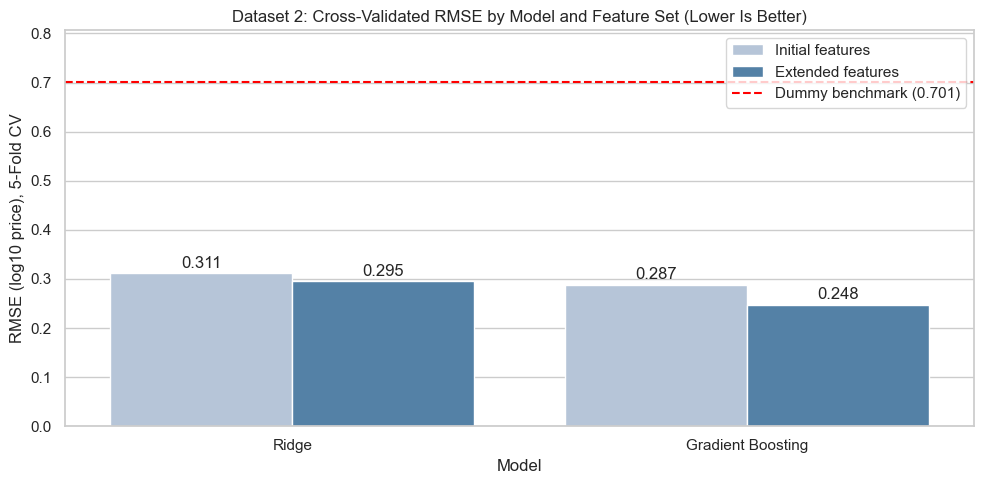

In [4]:
plot_data = cv_results[cv_results["Model"] != "Dummy (mean)"]
dummy_rmse = cv_results.loc[cv_results["Model"] == "Dummy (mean)", "CV RMSE (log10)"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_data, x="Model", y="CV RMSE (log10)", hue="Feature set",
            palette=["lightsteelblue", "steelblue"], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2)
ax.axhline(dummy_rmse, color="red", linestyle="--", label=f"Dummy benchmark ({dummy_rmse:.3f})")
ax.set_title("Dataset 2: Cross-Validated RMSE by Model and Feature Set (Lower Is Better)")
ax.set_xlabel("Model")
ax.set_ylabel("RMSE (log10 price), 5-Fold CV")
ax.set_ylim(0, dummy_rmse * 1.15)
ax.legend(title="", loc="upper right")
plt.tight_layout()
plt.show()

**Observation:** 
- **The initial baseline is reproduced:** Ridge with the initial features has a CV RMSE of 0.311, close to the initial report's test RMSE of 0.31.
- **Gradient Boosting improves on it with the same features** (0.287), likely thanks to interactions and non-linear effects.
- **The extended features help both models**, and most of all Gradient Boosting (0.248, a 20% lower error than the baseline). The extra variables (seller information, face area, dial, crystal) add predictive information, although part of the seller signal turns out to be the model recognizing individual dealers (section 6).
- Gradient Boosting with extended features fits the training data much more closely than it validates (0.145 vs 0.248). Its validation error is still clearly the best, so the extra flexibility generalizes, but the gap is larger than for the Dataset 1 model; section 6 suggests part of the reason (the seller variables let the model recognize individual dealers).

## 4. Test-Set Results vs the Initial Baseline
The best estimator from each grid search (already re-trained on the full training set by `GridSearchCV`) is scored once on the hold-out test set.

In [5]:
test_rows = []
for (model_name, feature_set), search in searches.items():
    predictions = search.predict(test_df[feature_columns(feature_set)])
    test_rows.append({"Model": f"{model_name} [{feature_set}]", **regression_metrics(test_df[TARGET], predictions)})

test_results = pd.DataFrame(test_rows).set_index("Model").sort_values("RMSE (log10)")
display(test_results.style.format({"RMSE (log10)": "{:.3f}", "R² (log)": "{:.3f}", "MAE (log10)": "{:.3f}",
                                   "MdAPE": "{:.1%}", "Within ±25%": "{:.1%}"}))

,RMSE (log10),R² (log),MAE (log10),MdAPE,Within ±25%
Model,,,,,
Gradient Boosting [Extended features],0.241,0.881,0.174,28.9%,44.5%
Gradient Boosting [Initial features],0.284,0.835,0.207,34.5%,38.0%
Ridge [Extended features],0.290,0.828,0.214,36.5%,36.1%
Ridge [Initial features],0.305,0.809,0.225,38.6%,34.4%
Dummy (mean) [Initial features],0.699,-0.000,0.556,85.8%,13.3%


**Interpretation:** The test set confirms the cross-validation ranking.
- **Like-for-like with the initial report** (Ridge, initial features): R² 0.81, median error 38.6%, close to the initial report's 0.80 and 37%.
- **Final model on Dataset 2** (Gradient Boosting, extended features): **R² 0.88, median error 28.9%**, with 44.5% of predictions within ±25% (vs 34.4% for the baseline).
- Dataset 2 is still harder to predict than Dataset 1 (median error 20% there) most likely because it has **no model names** (Notebook 2 showed how much the model line adds on Dataset 1).

## 5. Feature Importance
Permutation importance of the best model on the test set: each original feature is shuffled in turn (10 repeats) and the **increase in RMSE** is measured. A larger increase means the model relies more on that feature.

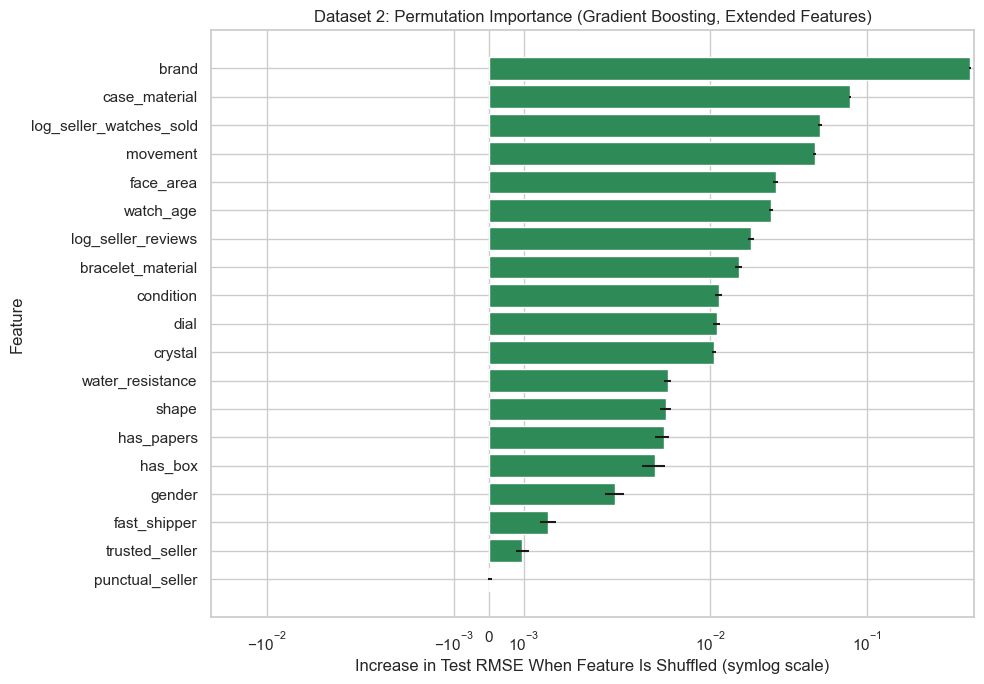

Feature,RMSE increase,Std
brand,0.4515,0.0051
case_material,0.0775,0.0012
log_seller_watches_sold,0.0499,0.0015
movement,0.0462,0.0013
face_area,0.0261,0.0009
watch_age,0.0244,0.0006
log_seller_reviews,0.0182,0.0009
bracelet_material,0.0152,0.0008
condition,0.0113,0.0006
dial,0.0110,0.0005


In [6]:
best_market_model = searches[("Gradient Boosting", "Extended features")].best_estimator_
X_test_ext = test_df[feature_columns("Extended features")]

importance = permutation_importance(best_market_model, X_test_ext, test_df[TARGET], n_repeats=10,
                                    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1)
importance_df = (pd.DataFrame({"Feature": X_test_ext.columns, "RMSE increase": importance.importances_mean,
                               "Std": importance.importances_std})
                 .sort_values("RMSE increase", ascending=False))

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importance_df["Feature"], importance_df["RMSE increase"], xerr=importance_df["Std"], color="seagreen")
ax.invert_yaxis()
ax.set_xscale("symlog", linthresh=0.005)   # keeps small importances visible next to brand
ax.set_title("Dataset 2: Permutation Importance (Gradient Boosting, Extended Features)")
ax.set_xlabel("Increase in Test RMSE When Feature Is Shuffled (symlog scale)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance_df.head(10).style.format({"RMSE increase": "{:.4f}", "Std": "{:.4f}"}).hide(axis="index"))

**Observation:** **Brand** dominates again (RMSE +0.45 when shuffled). It is followed by **case material**, the number of watches the seller has sold, **movement**, **face area** and **watch age**. Seller reviews and watches sold are almost the same variable (Spearman correlation 0.995, see section 6), so each one's importance here understates their combined effect: when one is shuffled, the model can still partly rely on the other. Box and papers do not appear in the top 10, but section 6 shows that they are still associated with a sizeable price difference.

## 6. What Are Box, Papers and Seller Reputation Worth?
The tuned model can answer "what if" questions. For every test listing, the model predicts the price **twice**, changing only one feature (for example, *without* box & papers vs *with* box & papers) and keeping everything else, including the brand, condition and seller, the same. The ratio of the two predictions is the model's estimate of that feature's value **for that specific watch**.

These are *associations learned from asking prices*, not proof of cause and effect, but because all other recorded features are held fixed they are much closer to a like-for-like comparison than the raw medians in Notebook 1.

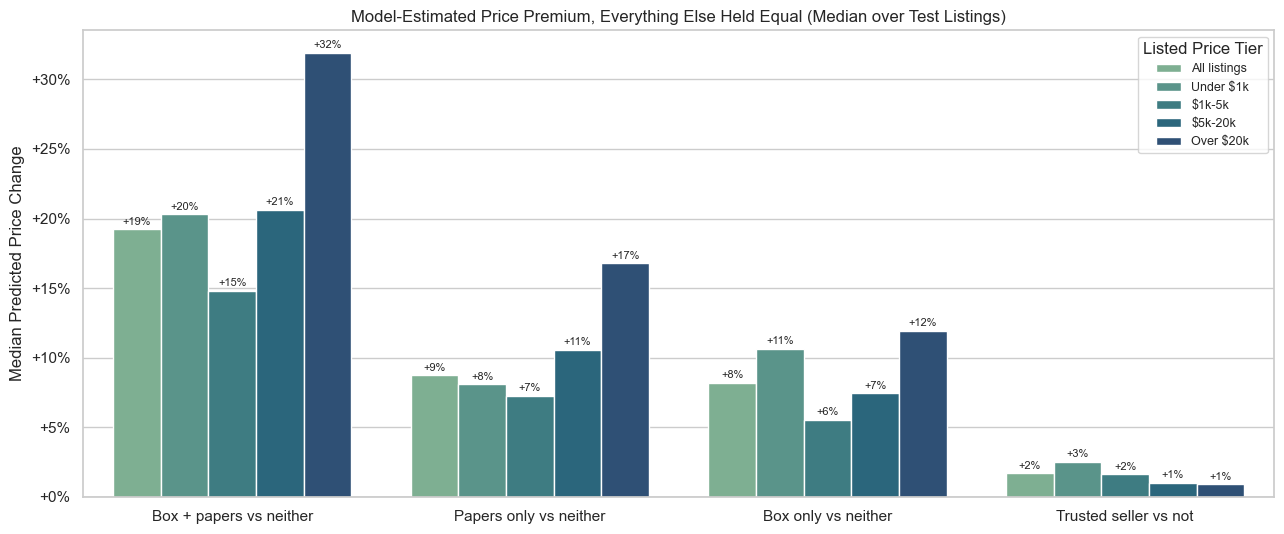

Tier,All listings,Under $1k,$1k-5k,$5k-20k,Over $20k
Scenario,,,,,
Box + papers vs neither,+19.2%,+20.3%,+14.8%,+20.6%,+31.9%
Box only vs neither,+8.2%,+10.6%,+5.6%,+7.4%,+11.9%
Papers only vs neither,+8.7%,+8.1%,+7.2%,+10.5%,+16.8%
Trusted seller vs not,+1.7%,+2.5%,+1.6%,+1.0%,+0.9%


In [7]:
def what_if_premium(model, data, changes_off, changes_on):
    """Predicted price ratio (on / off) per listing, changing only the given columns."""
    data_off, data_on = data.copy(), data.copy()
    for column, value in changes_off.items():
        data_off[column] = value
    for column, value in changes_on.items():
        data_on[column] = value
    return pd.Series(10 ** (model.predict(data_on) - model.predict(data_off)), index=data.index)


scenarios = {
    "Box + papers vs neither": ({"has_box": 0, "has_papers": 0}, {"has_box": 1, "has_papers": 1}),
    "Papers only vs neither": ({"has_box": 0, "has_papers": 0}, {"has_box": 0, "has_papers": 1}),
    "Box only vs neither": ({"has_box": 0, "has_papers": 0}, {"has_box": 1, "has_papers": 0}),
    "Trusted seller vs not": ({"trusted_seller": 0}, {"trusted_seller": 1}),
}
# Price tiers based on the listed price, so premiums can be compared for cheap and expensive watches
price_tier = pd.cut(test_df["price"], bins=[0, 1_000, 5_000, 20_000, np.inf],
                    labels=["Under $1k", "$1k-5k", "$5k-20k", "Over $20k"])

premium_rows = []
for scenario, (off, on) in scenarios.items():
    ratios = what_if_premium(best_market_model, X_test_ext, off, on)
    premium_rows.append({"Scenario": scenario, "Tier": "All listings", "Median premium": ratios.median() - 1})
    for tier, tier_ratios in ratios.groupby(price_tier, observed=True):
        premium_rows.append({"Scenario": scenario, "Tier": tier, "Median premium": tier_ratios.median() - 1})
premiums = pd.DataFrame(premium_rows)

fig, ax = plt.subplots(figsize=(13, 5.5))
sns.barplot(data=premiums, x="Scenario", y="Median premium", hue="Tier", palette="crest", ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:+.0%}" for v in container.datavalues], fontsize=8, padding=2)
ax.axhline(0, color="black", lw=0.8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_title("Model-Estimated Price Premium, Everything Else Held Equal (Median over Test Listings)")
ax.set_xlabel("")
ax.set_ylabel("Median Predicted Price Change")
ax.legend(title="Listed Price Tier", fontsize=9)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "box_papers_seller_premium.png", dpi=110, bbox_inches="tight")
plt.show()

display(premiums.pivot(index="Scenario", columns="Tier", values="Median premium")
        [["All listings", "Under $1k", "$1k-5k", "$5k-20k", "Over $20k"]].style.format("{:+.1%}"))

**Observation:** For the same watch, with the same recorded seller information:
- **A complete set (box + papers) adds about 19%** to the predicted price compared with a watch with neither, and it is largest for the most expensive watches: **about +32% above USD 20k**, compared with +20% under USD 1k, +15% for USD 1k-5k and +21% for USD 5k-20k.
- **Papers alone (+9%) and the box alone (+8%)** are each worth less than half of the full set. Together they are worth slightly more than the sum of the two separately (+19% vs about +17%).
- **The trusted-seller badge's own value cannot be measured reliably with this data.** The model gives it only about +2% when everything else is held equal, but the badge almost always goes with the same sellers (checked at the end of this section), and the seller counts in the model largely identify individual sellers. The model can therefore pick up the badge through the seller counts, and changing only the badge while keeping the same seller describes a combination it has rarely seen. The 16% raw gap in Notebook 1 could come from the watches being sold, from the sellers or from the badge itself; this data cannot separate them.

Distinct (reviews, watches sold) combinations: 3,152 across 31,914 listings; largest single combination: 416 listings
Spearman correlation, seller reviews vs watches sold: 0.995


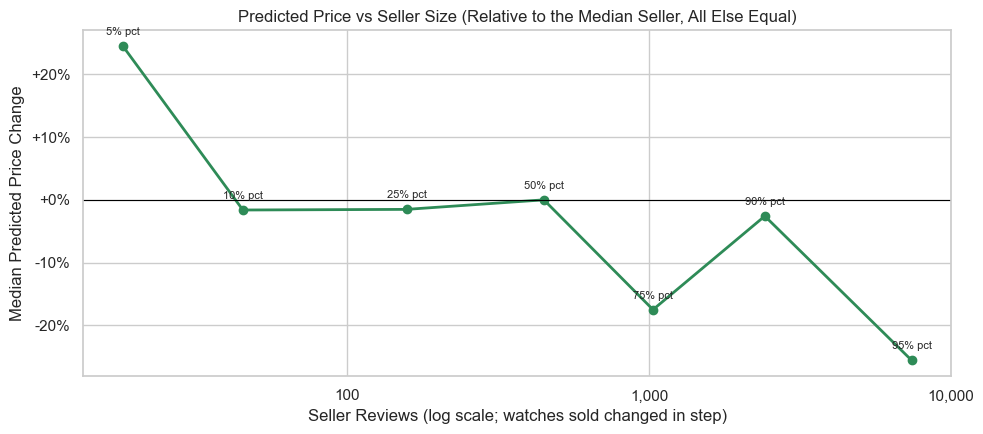

,seller reviews,watches sold,price change vs median seller
5% percentile,18,18,+24.5%
10% percentile,45,45,-1.6%
25% percentile,157,195,-1.5%
50% percentile,448,580,+0.0%
75% percentile,"1,031","1,433",-17.5%
90% percentile,"2,421","3,531",-2.6%
95% percentile,"7,436","14,642",-25.6%


In [8]:
# Seller size: reviews and watches sold are almost the same variable (Spearman correlation printed below),
# so they are changed together, using matching percentiles of each (e.g. the 10th percentile of both)
seller_counts = market[["seller_reviews", "seller_watches_sold"]].dropna()
print(f"Distinct (reviews, watches sold) combinations: {len(seller_counts.drop_duplicates()):,} "
      f"across {len(seller_counts):,} listings; largest single combination: "
      f"{seller_counts.value_counts().iloc[0]:,} listings")
print("Spearman correlation, seller reviews vs watches sold: "
      f"{market['seller_reviews'].corr(market['seller_watches_sold'], method='spearman'):.3f}")
percentiles = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
seller_levels = market[["seller_reviews", "seller_watches_sold"]].quantile(percentiles)


def predict_with_seller(level):
    return best_market_model.predict(X_test_ext.assign(log_seller_reviews=np.log1p(level["seller_reviews"]),
                                                       log_seller_watches_sold=np.log1p(level["seller_watches_sold"])))


reference = predict_with_seller(seller_levels.loc[0.50])
seller_effect = [np.median(10 ** (predict_with_seller(level) - reference)) - 1 for _, level in seller_levels.iterrows()]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(seller_levels["seller_reviews"], seller_effect, marker="o", color="seagreen", lw=2)
for (pct, level), effect in zip(seller_levels.iterrows(), seller_effect):
    ax.annotate(f"{pct:.0%} pct", (level["seller_reviews"], effect), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_title("Predicted Price vs Seller Size (Relative to the Median Seller, All Else Equal)")
ax.set_xlabel("Seller Reviews (log scale; watches sold changed in step)")
ax.set_ylabel("Median Predicted Price Change")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"seller reviews": seller_levels["seller_reviews"].values,
                      "watches sold": seller_levels["seller_watches_sold"].values,
                      "price change vs median seller": seller_effect},
                     index=[f"{p:.0%} percentile" for p in percentiles])
        .style.format({"seller reviews": "{:,.0f}", "watches sold": "{:,.0f}",
                       "price change vs median seller": "{:+.1%}"}))

**Observation:** there is **no consistent seller-size effect**. The curve jumps up and down (+25% at the 5th percentile, -18% at the 75th, -26% at the 95th) instead of following a trend. The reason is in the printout above: the pair (number of reviews, number of watches sold) takes only about 3,150 distinct values, and the most common pair appears on 416 listings, most likely all from a single large dealer. The model is therefore effectively **recognizing individual sellers** and their pricing habits (for example, at the 95th percentile, which is that most common pair, the model predicts prices about 26% below the median seller for the same watches), not learning a general rule about seller size. This likely also explains why the seller variables rank high in permutation importance and why this model overfits more than the Dataset 1 model. A cleaner study would need a proper seller ID and seller-level validation (all listings of a seller in either training or test data).

In [9]:
# Can the trusted-seller badge be separated from the seller? Share of (reviews, watches sold) combinations
# in which every listing has the same badge, and the badge share among listings without seller counts
badge_per_seller = (market.dropna(subset=["seller_reviews", "seller_watches_sold"])
                    .groupby(["seller_reviews", "seller_watches_sold"])["trusted_seller"].nunique())
print(f"Seller combinations in which all listings have the same badge: {(badge_per_seller == 1).mean():.0%} "
      f"of {len(badge_per_seller):,}")
print("Trusted-seller share among listings without seller counts: "
      f"{market.loc[market['seller_reviews'].isna(), 'trusted_seller'].mean():.0%}")

Seller combinations in which all listings have the same badge: 97% of 3,152
Trusted-seller share among listings without seller counts: 3%


## 7. Summary
1. **Like-for-like improvement over the initial report:** on the same dataset, the tuned Gradient Boosting model with extended features reaches R² 0.88 and a median error of 29%, against R² 0.81 and 39% for the initial Ridge baseline re-run on the same split.
2. **Box and papers are worth about 19% of a watch's price** (all else equal), and about 32% for watches above USD 20,000. Papers or box alone are worth about 8-9% each.
3. **The trusted-seller badge's own value could not be measured.** The model gives it only about 2%, but the badge almost always goes with the same sellers, so its effect cannot be separated from who the seller is.
4. **No general seller-size effect was found.** The seller counts mostly identify individual dealers, whose pricing differs (the model prices some dealers' watches well below comparable ones), so the model learns dealer-specific habits rather than a rule a seller could act on.
5. **Brand remains the dominant feature** in a dataset without model names, which likely explains why Dataset 2 is harder to predict (29% median error) than Dataset 1 (20%).